# 01 · Exploratory Data Analysis — UCI Heart Disease (4 sites)

**Goal:** understand data quality, class balance and feature–target relationships before modelling.

Data: all four UCI collection sites (Cleveland, Hungary, Switzerland, VA Long Beach), cleaned by `src/data_prep.py`.
Figures are saved to `report/figures/` for the final report.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_prep import CATEGORICAL_COLS, NUMERIC_COLS, TARGET, clean, load_raw

FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
SITE_ORDER = ["cleveland", "hungary", "switzerland", "va_long_beach"]
TARGET_PALETTE = {0: "#4C9F70", 1: "#C8553D"}

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load and clean

In [3]:
raw = load_raw()
df = clean(raw)
print(f"raw: {raw.shape}  cleaned: {df.shape}")
df.head()

raw: (920, 16)  cleaned: (918, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,site,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,cleveland,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,cleveland,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,cleveland,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,cleveland,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,cleveland,0


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,918.0,NaN,NaN,NaN,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
sex,918.0,<NA>,<NA>,<NA>,0.78976,0.407701,0.0,1.0,1.0,1.0,1.0
cp,918.0,<NA>,<NA>,<NA>,3.251634,0.931031,1.0,3.0,4.0,4.0,4.0
trestbps,858.0,NaN,NaN,NaN,132.291375,18.532294,80.0,120.0,130.0,140.0,200.0
chol,717.0,NaN,NaN,NaN,246.871688,58.558668,85.0,210.0,240.0,277.0,603.0
fbs,828.0,<NA>,<NA>,<NA>,0.166667,0.372903,0.0,0.0,0.0,0.0,1.0
restecg,916.0,<NA>,<NA>,<NA>,0.604803,0.806354,0.0,0.0,0.0,1.0,2.0
thalach,863.0,NaN,NaN,NaN,137.542294,25.936524,60.0,120.0,140.0,157.0,202.0
exang,863.0,<NA>,<NA>,<NA>,0.38934,0.487883,0.0,0.0,0.0,1.0,1.0
oldpeak,856.0,NaN,NaN,NaN,0.880841,1.091673,-2.6,0.0,0.5,1.5,6.2


## 2. Missing values by site

The raw download already showed that `ca`, `thal` and `slope` are mostly empty outside Cleveland.
After cleaning, `chol` is also missing for every Swiss patient (they were recorded as 0).

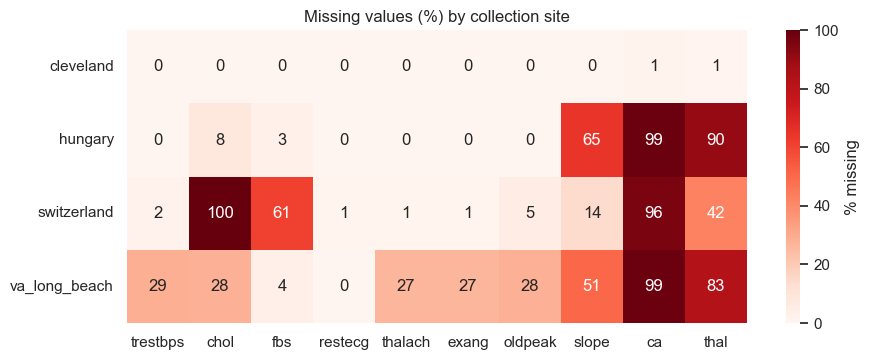

,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
site,,,,,,,,,,
cleveland,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.3,0.7
hungary,0.3,7.5,2.7,0.3,0.3,0.3,0.0,64.5,99.0,90.4
switzerland,1.6,100.0,61.0,0.8,0.8,0.8,4.9,13.8,95.9,42.3
va_long_beach,28.6,28.1,3.5,0.0,26.6,26.6,28.1,50.8,99.0,82.9


In [5]:
miss = (df.drop(columns=["site", TARGET]).isna()
          .groupby(df["site"]).mean().mul(100).reindex(SITE_ORDER))
miss = miss.loc[:, miss.sum() > 0]

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(miss, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing values (%) by collection site")
ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "01_missing_by_site"); plt.show()
miss.round(1)

## 3. Class balance — overall and by site

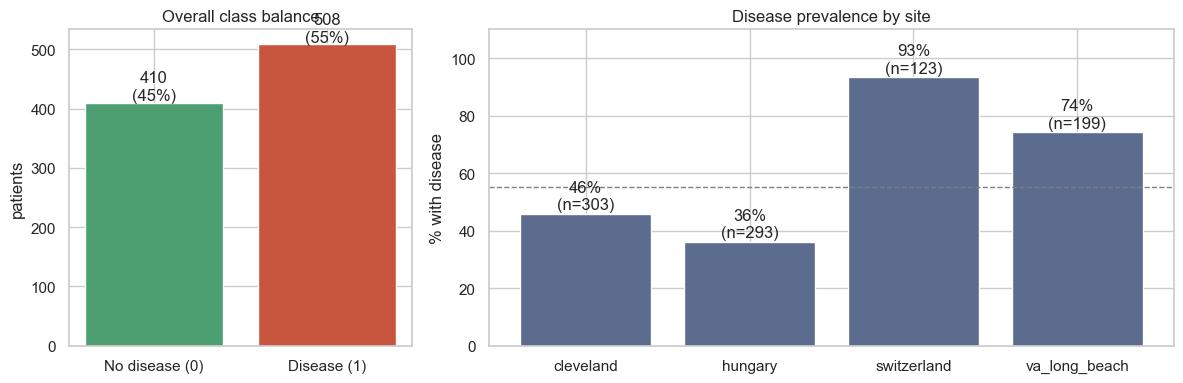

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})

counts = df[TARGET].value_counts().sort_index()
axes[0].bar(["No disease (0)", "Disease (1)"], counts.values,
            color=[TARGET_PALETTE[0], TARGET_PALETTE[1]])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5, f"{v}\n({v / len(df):.0%})", ha="center")
axes[0].set_title("Overall class balance"); axes[0].set_ylabel("patients")

rate = df.groupby("site")[TARGET].agg(["mean", "size"]).reindex(SITE_ORDER)
axes[1].bar(rate.index, rate["mean"] * 100, color="#5B6C8F")
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    axes[1].text(i, m * 100 + 1.5, f"{m:.0%}\n(n={n})", ha="center")
axes[1].axhline(df[TARGET].mean() * 100, ls="--", c="grey", lw=1)
axes[1].set_ylim(0, 110); axes[1].set_ylabel("% with disease")
axes[1].set_title("Disease prevalence by site")
fig.tight_layout(); save(fig, "02_class_balance"); plt.show()

**Observation:** overall the classes are reasonably balanced, but prevalence differs sharply by site.
A model given `site` as a feature could learn "Switzerland ⇒ disease" — a shortcut that would not hold
for a new patient at a new hospital. This is an argument for **excluding `site` from the model features**
and using it only for evaluation (e.g. leave-one-site-out validation).

## 4. Numeric features — distributions by target

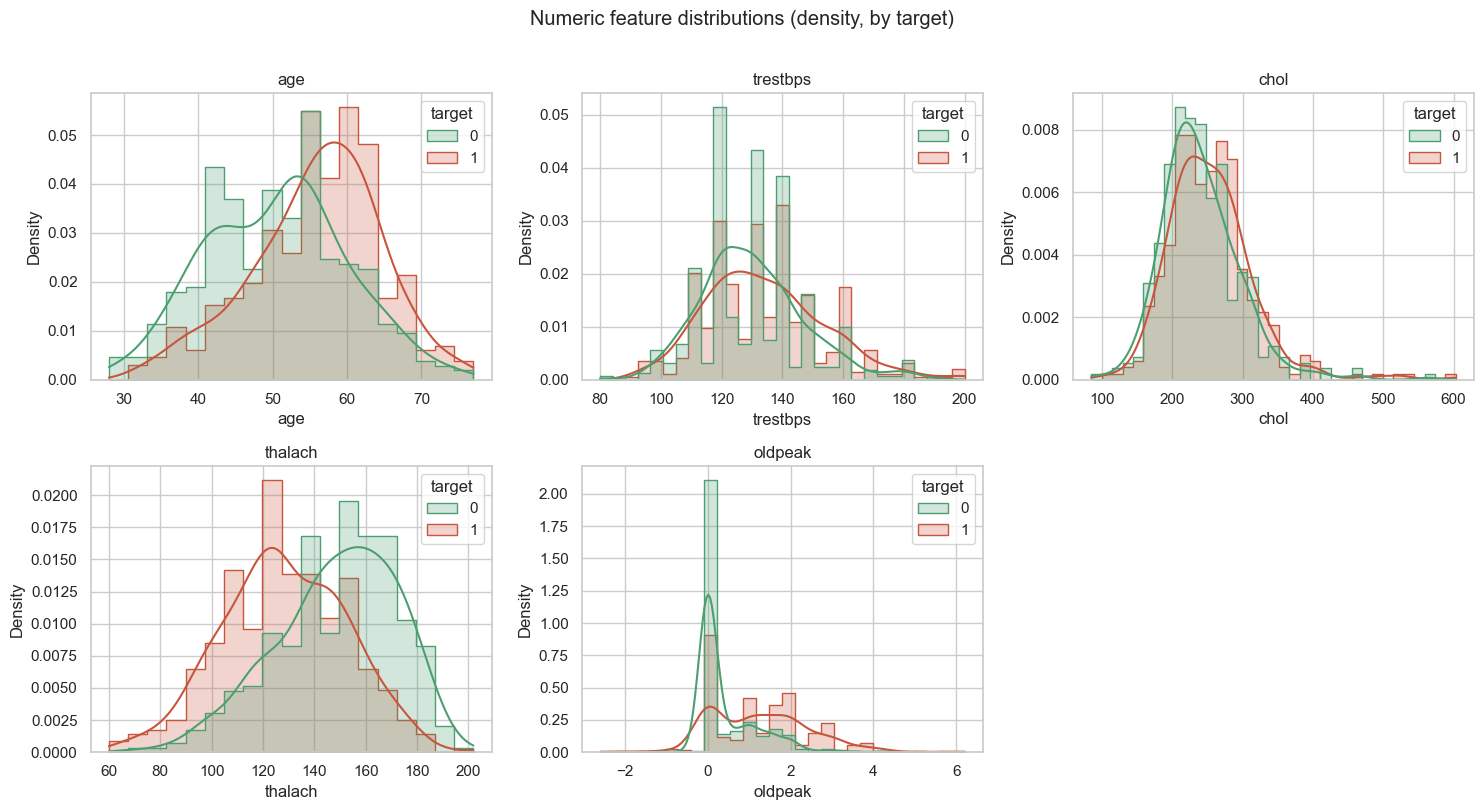

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.histplot(data=df, x=col, hue=TARGET, palette=TARGET_PALETTE, kde=True,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
fig.suptitle("Numeric feature distributions (density, by target)", y=1.01)
fig.tight_layout(); save(fig, "03_numeric_histograms"); plt.show()

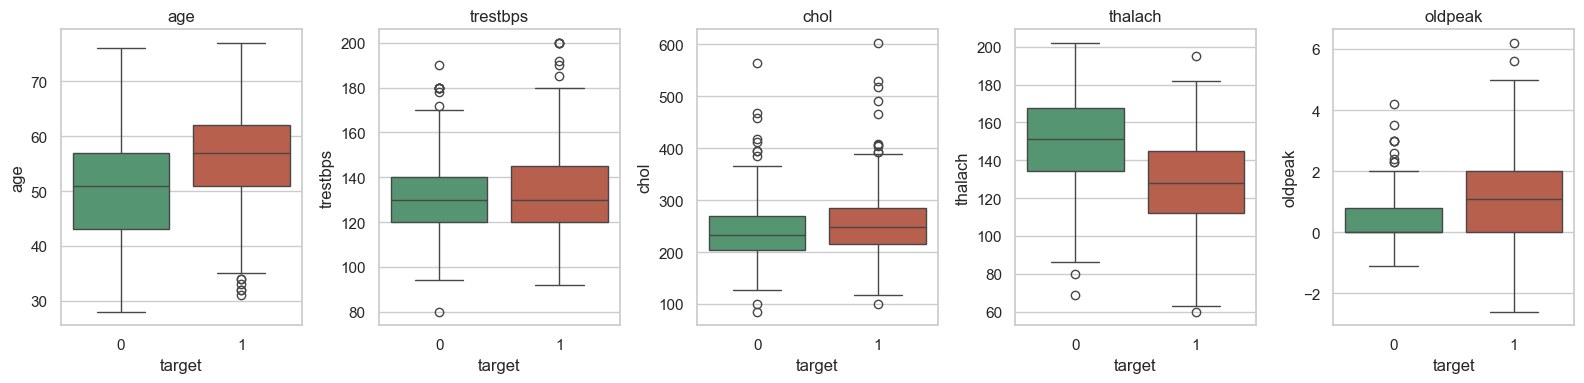

In [8]:
fig, axes = plt.subplots(1, len(NUMERIC_COLS), figsize=(16, 4))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=TARGET_PALETTE,
                legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel("target")
fig.tight_layout(); save(fig, "04_numeric_boxplots"); plt.show()

## 5. Categorical features — disease rate per category

/var/folders/rx/fszq0zzd321d5mfrgyv3nw240000gn/T/ipykernel_25033/1259823606.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  tab = (df.assign(**{col: df[col].astype("object").fillna("missing")})
/var/folders/rx/fszq0zzd321d5mfrgyv3nw240000gn/T/ipykernel_25033/1259823606.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  tab = (df.assign(**{col: df[col].astype("object").fillna("missing")})


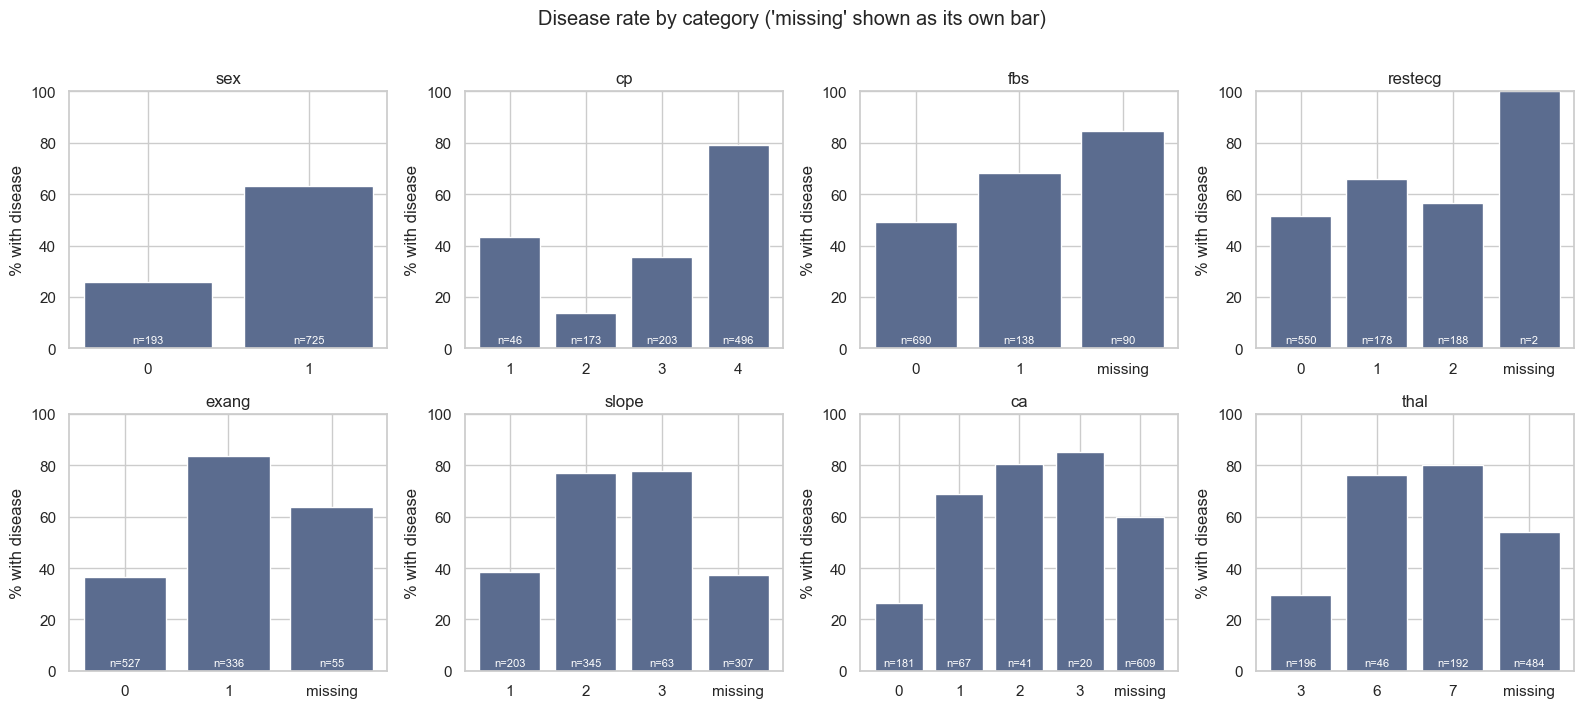

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, CATEGORICAL_COLS):
    tab = (df.assign(**{col: df[col].astype("object").fillna("missing")})
             .groupby(col)[TARGET].agg(["mean", "size"]))
    ax.bar(tab.index.astype(str), tab["mean"] * 100, color="#5B6C8F")
    for i, n in enumerate(tab["size"]):
        ax.text(i, 2, f"n={n}", ha="center", color="white", fontsize=8)
    ax.set_title(col); ax.set_ylim(0, 100); ax.set_ylabel("% with disease")
fig.suptitle("Disease rate by category ('missing' shown as its own bar)", y=1.01)
fig.tight_layout(); save(fig, "05_categorical_rates"); plt.show()

Note the `missing` bars: if missingness itself correlates with the target, it carries signal
(largely because missingness is site-driven). That supports adding **missing-indicator** features
rather than silently imputing.

## 6. Correlations

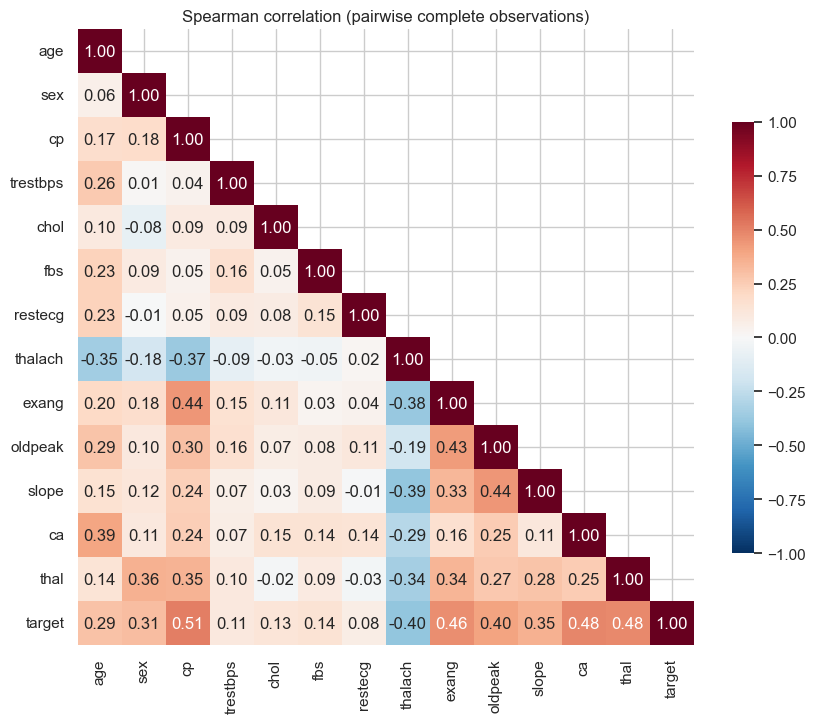

cp          0.512
ca          0.484
thal        0.484
exang       0.462
oldpeak     0.402
thalach    -0.398
slope       0.353
sex         0.305
age         0.290
fbs         0.143
chol        0.128
trestbps    0.107
restecg     0.076
Name: target, dtype: float64

In [10]:
corr = df.drop(columns=["site"]).apply(pd.to_numeric, errors="coerce").corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation (pairwise complete observations)")
save(fig, "06_correlation_heatmap"); plt.show()

corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

## 7. Save cleaned dataset

In [12]:
out = ROOT / "data" / "processed" / "heart_disease_clean.csv"
df.to_csv(out, index=False)
print(f"saved {len(df)} rows -> {out.relative_to(ROOT)}")

saved 918 rows -> data/processed/heart_disease_clean.csv


## 8. Findings → decisions for modelling

*Fill in from your own reading of the plots above — these drive `src/features.py`.*

| Finding | Decision |
|---|---|
| `ca` ~99% and `thal` ~83–90% missing outside Cleveland | _drop / keep with indicator / Cleveland-only model?_ |
| `slope` heavily missing in Hungary and VA | _impute + indicator?_ |
| `chol` missing for all of Switzerland | _median impute + indicator?_ |
| Prevalence varies 36% → 93% by site | _exclude `site` from features; use for leave-one-site-out CV?_ |
| Strongest target correlations: ... | ... |